# 1. Simulador de dados sintéticos: geração de mapa com as ocorrências e seus tempos de processamento

## 1.1. Geração de pontos em um mapa a partir do geojson do município selecionado

In [ ]:
# ==========================================================
# BISS - Dataset completo + pontos no polígono + mapa interativo
# ==========================================================

!pip -q install geopandas shapely pyogrio pandas numpy folium

import geopandas as gpd
import pandas as pd
import numpy as np
import random
from shapely.geometry import Point
import folium

# ----------------------------------------------------------
# 1. Carregar malha municipal de SP
# ----------------------------------------------------------

url = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-35-mun.json"

gdf = gpd.read_file(url)

gdf = gdf.sort_values("name").reset_index(drop=True)

print("Municípios carregados:", len(gdf))

# ----------------------------------------------------------
# 2. Função para gerar pontos dentro do polígono
# ----------------------------------------------------------

def gerar_pontos_no_poligono(poligono, n_pontos=500, seed=0):

    random.seed(seed)

    minx, miny, maxx, maxy = poligono.bounds

    pontos = []

    while len(pontos) < n_pontos:

        x = random.uniform(minx, maxx)
        y = random.uniform(miny, maxy)

        ponto = Point(x, y)

        if poligono.contains(ponto):
            pontos.append((y, x))  # lat, lon

    return pontos


# ----------------------------------------------------------
# 3. Criar dataset base de municípios
# ----------------------------------------------------------

municipios = []

for i, row in gdf.iterrows():

    municipio_id = i + 1

    nome = row["name"]
    codigo_ibge = row["id"]
    poligono = row["geometry"]

    minx, miny, maxx, maxy = poligono.bounds

    pontos = gerar_pontos_no_poligono(poligono, 100, seed=municipio_id)

    municipios.append({

        "municipio_index": municipio_id,
        "municipio_nome": nome,
        "codigo_ibge": codigo_ibge,

        "min_lon": minx,
        "min_lat": miny,
        "max_lon": maxx,
        "max_lat": maxy,

        "pontos_amostra": pontos,
        "geometry": poligono

    })

df_municipios = pd.DataFrame(municipios)

# ----------------------------------------------------------
# 4. Parâmetros BISS
# ----------------------------------------------------------

metodos_cluster = {
    1:"KMeans",
    2:"MiniBatchKMeans",
    3:"SpectralClustering",
    4:"Agglomerative",
    5:"BisectingKMeans",
    6:"BIRCH"
}

modelos_localizacao = {
    1:"P_Medianas",
    2:"P_Centros",
    3:"Capacitado"
}

# ----------------------------------------------------------
# 5. Gerar dataset completo BISS
# ----------------------------------------------------------

dataset_biss = []

for _, row in df_municipios.iterrows():

    m = int(row["municipio_index"])

    for c in metodos_cluster:
        for l in modelos_localizacao:

            codigo = f"BISS-M{m:03d}-C{c}-L{l}"

            dataset_biss.append({

                "BISS_ID": codigo,

                "municipio_index": m,
                "municipio_nome": row["municipio_nome"],
                "codigo_ibge": row["codigo_ibge"],

                "cluster_metodo_id": c,
                "cluster_metodo_nome": metodos_cluster[c],

                "modelo_loc_id": l,
                "modelo_loc_nome": modelos_localizacao[l],

                "min_lat": row["min_lat"],
                "min_lon": row["min_lon"],
                "max_lat": row["max_lat"],
                "max_lon": row["max_lon"],

                "pontos_amostra": row["pontos_amostra"]

            })

df_biss = pd.DataFrame(dataset_biss)

print("Total de work units:", len(df_biss))

# ----------------------------------------------------------
# 6. Salvar dataset
# ----------------------------------------------------------

df_biss.to_csv("dataset_biss_sp_com_pontos.csv", index=False)

print("Dataset salvo: dataset_biss_sp_com_pontos.csv")

# ----------------------------------------------------------
# 7. Visualização automática em mapa interativo
# ----------------------------------------------------------

municipio_visualizar = df_municipios.iloc[100]  # exemplo automático

poligono = municipio_visualizar["geometry"]
pontos = municipio_visualizar["pontos_amostra"]

centro_lat = poligono.centroid.y
centro_lon = poligono.centroid.x

mapa = folium.Map(location=[centro_lat, centro_lon], zoom_start=10)

# desenhar polígono do município
folium.GeoJson(
    poligono,
    name="Limite municipal",
    style_function=lambda x: {"color":"blue","weight":2,"fillOpacity":0.1}
).add_to(mapa)

# desenhar bounding box
min_lon = municipio_visualizar["min_lon"]
min_lat = municipio_visualizar["min_lat"]
max_lon = municipio_visualizar["max_lon"]
max_lat = municipio_visualizar["max_lat"]

bbox = [
    [min_lat, min_lon],
    [min_lat, max_lon],
    [max_lat, max_lon],
    [max_lat, min_lon],
    [min_lat, min_lon]
]

folium.PolyLine(bbox, color="red", weight=2, tooltip="Bounding Box").add_to(mapa)

# plotar pontos
for lat, lon in pontos:

    folium.CircleMarker(
        location=[lat, lon],
        radius=3,
        color="green",
        fill=True,
        fill_opacity=0.7
    ).add_to(mapa)

# popup
folium.Marker(
    [centro_lat, centro_lon],
    popup=f"Município: {municipio_visualizar['municipio_nome']}"
).add_to(mapa)

mapa

Municípios carregados: 645
Total de work units: 11610
Dataset salvo: dataset_biss_sp_com_pontos.csv


In [ ]:
len(pontos)

100

## 1.2. Adicionando os tempos de processamento aos pontos adicionados

In [ ]:
from enum import Enum
from typing import List, Tuple

class DistKind(Enum):
    EXPONENTIAL = 'exponential'
    NORMAL = 'normal'
    LOGNORMAL = 'lognormal'

def create_occurrence_table_from_points(
    input_pontos: List[Tuple[float, float]],
    city_info: pd.Series,
    t1_dist=DistKind.EXPONENTIAL, t1_p1=5.0, t1_p2=0.0, t1_p3=0.0,
    t2_dist=DistKind.NORMAL, t2_p1=2.0, t2_p2=0.5, t2_p3=0.0,
    t4_dist=DistKind.NORMAL, t4_p1=10.0, t4_p2=3.0, t4_p3=0.0,
    t5_dist=DistKind.LOGNORMAL, t5_p1=2.3, t5_p2=0.5, t5_p3=0.0
) -> pd.DataFrame:
    """
    Cria uma tabela de ocorrências a partir de uma lista de pontos (latitude, longitude).

    Args:
        input_pontos (List[Tuple[float, float]]): Uma lista de tuplas (latitude, longitude) representando os pontos de ocorrência.
        city_info (pd.Series): Uma Series do pandas contendo as informações da cidade,
                               incluindo 'Municipio', 'Populacao_2024', 'lat', 'lon' e 'geometry'.
        t1_dist, t1_p1, ...: Parâmetros para a distribuição de T1 (tempo entre chegadas).
        t2_dist, t2_p1, ...: Parâmetros para a distribuição de T2 (tempo de despacho).
        t4_dist, t4_p1, ...: Parâmetros para a distribuição de T4 (tempo de atendimento local e envio ao hospital).
        t5_dist, t5_p1, ...: Parâmetros para a distribuição de T5 (tempo para higienização e liberação da viatura).

    Returns:
        pd.DataFrame: Um DataFrame contendo as ocorrências geradas com os tempos T1 a T5 e detalhes de chegada.
    """
    # Adiciona 'Populacao_2024' se estiver faltando (necessário para generate_occurrences)
    if 'Populacao_2024' not in city_info:
        city_info = city_info.copy()
        # Usando um valor padrão de 0 ou um valor representativo se a população não for crítica para a lógica
        # Aqui, vamos usar um valor padrão como 200000 para que a função continue sem erro.
        # Em um cenário real, você pode querer um tratamento de erro mais robusto ou exigir a população.
        city_info['Populacao_2024'] = 200000

    num_points = len(input_pontos)
    city_geometry = city_info['geometry']

    df_occurrences = generate_occurrences(
        city_row=city_info,
        n=num_points,
        city_geometry=city_geometry,
        dist_t1=t1_dist, t1_p1=t1_p1, t1_p2=t1_p2, t1_p3=t1_p3,
        dist_t2=t2_dist, t2_p1=t2_p1, t2_p2=t2_p2, t2_p3=t2_p3,
        dist_t4=t4_dist, t4_p1=t4_p1, t4_p2=t4_p2, t4_p3=t4_p3,
        dist_t5=t5_dist, t5_p1=t5_p1, t5_p2=t5_p2, t5_p3=t5_p3,
        existing_pts=input_pontos
    )
    return df_occurrences

In [ ]:
import numpy as np
import pandas as pd
import random
from shapely.geometry import Point
from typing import List, Tuple

def get_random_points_in_polygon(polygon, n, seed=None):
    """
    Generates 'n' random points within a given Shapely polygon.
    """
    if seed is not None:
        random.seed(seed)

    minx, miny, maxx, maxy = polygon.bounds
    points = []

    while len(points) < n:
        x = random.uniform(minx, maxx)
        y = random.uniform(miny, maxy)
        p = Point(x, y)
        if polygon.contains(p):
            points.append((y, x)) # Return as (lat, lon)
    return points

def generate_time_value(dist_kind, p1, p2, p3):
    """
    Generates a single time value based on the specified distribution.
    p1, p2, p3 are parameters for the distribution.
    """
    if dist_kind == DistKind.EXPONENTIAL:
        # p1: scale (beta), p2, p3 not used
        return np.random.exponential(scale=p1)
    elif dist_kind == DistKind.NORMAL:
        # p1: mean, p2: standard deviation, p3 not used
        return np.random.normal(loc=p1, scale=p2)
    elif dist_kind == DistKind.LOGNORMAL:
        # p1: mean of lognormal distribution, p2: std dev of lognormal distribution, p3 not used
        # np.random.lognormal takes mean and sigma of the underlying normal distribution
        # If p1 and p2 are mean and std of the lognormal, need to convert:
        # mu = log(mean^2 / sqrt(std^2 + mean^2))
        # sigma = sqrt(log(1 + (std^2 / mean^2)))
        # For simplicity, assuming p1 and p2 are mu and sigma of the underlying normal for now.
        return np.random.lognormal(mean=p1, sigma=p2)
    else:
        raise ValueError(f"Unknown distribution kind: {dist_kind}")

def generate_occurrences(
    city_row: pd.Series,
    n: int,
    city_geometry: 'Polygon',
    dist_t1: DistKind, t1_p1: float, t1_p2: float, t1_p3: float,
    dist_t2: DistKind, t2_p1: float, t2_p2: float, t2_p3: float,
    dist_t4: DistKind, t4_p1: float, t4_p2: float, t4_p3: float,
    dist_t5: DistKind, t5_p1: float, t5_p2: float, t5_p3: float,
    existing_pts: List[Tuple[float, float]] = None
) -> pd.DataFrame:
    """
    Generates a DataFrame of occurrences with simulated processing times.

    Args:
        city_row (pd.Series): Information about the city.
        n (int): Number of occurrences to generate.
        city_geometry (Polygon): Shapely Polygon object representing the city's boundary.
        dist_tX, tX_p1, tX_p2, tX_p3: Distribution parameters for T1, T2, T4, T5.
        existing_pts (List[Tuple[float, float]], optional): If provided, these points are used
                                                           instead of generating new ones.

    Returns:
        pd.DataFrame: A DataFrame with occurrence details and simulated times.
    """

    if existing_pts:
        points = existing_pts
    else:
        # Use city_row's ID or index for seeding if available and no existing_pts
        seed_value = city_row.get('municipio_index', 42) # Default seed if not found
        points = get_random_points_in_polygon(city_geometry, n, seed=seed_value)

    data = []
    for i, (lat, lon) in enumerate(points):
        t1 = generate_time_value(dist_t1, t1_p1, t1_p2, t1_p3)
        t2 = generate_time_value(dist_t2, t2_p1, t2_p2, t2_p3)
        t4 = generate_time_value(dist_t4, t4_p1, t4_p2, t4_p3)
        t5 = generate_time_value(dist_t5, t5_p1, t5_p2, t5_p3)

        data.append({
            'ID': f"{city_row['municipio_nome']}-{i:04d}",
            'lat': lat,
            'lon': lon,
            'T1': t1,
            'T2': t2,
            'T4': t4,
            'T5': t5,
            'municipio_nome': city_row['municipio_nome'],
            'Populacao_2024': city_row.get('Populacao_2024', None) # Get population if it exists
        })

    df = pd.DataFrame(data)
    return df

## 1.3. Exemplo de uso da nova função com a variável 'pontos'

In [ ]:
# A variável 'pontos' foi gerada na célula 'Zn3kFs-HPsWX' e a 'campinas_row' na célula 'e9633f77'.
# Usamos 'municipio_visualizar' como base para as informações da cidade.

df_final_ocorrencias = create_occurrence_table_from_points(input_pontos=pontos, city_info=municipio_visualizar)

print("Tabela de ocorrências gerada a partir da variável 'pontos':")
display(df_final_ocorrencias.head())

Tabela de ocorrências gerada a partir da variável 'pontos':


,ID,lat,lon,T1,T2,T4,T5,municipio_nome,Populacao_2024
0,Campinas-0000,-22.840905,-47.043604,1.145350,1.540692,9.780463,8.376660,Campinas,200000
1,Campinas-0001,-22.987483,-47.152249,4.929483,2.410142,15.388296,4.810166,Campinas,200000
2,Campinas-0002,-22.831299,-47.120423,0.379293,2.987134,8.454017,17.046337,Campinas,200000
3,Campinas-0003,-22.904539,-47.086880,1.787925,2.611866,9.229068,10.009031,Campinas,200000
4,Campinas-0004,-22.849546,-47.104293,3.281820,1.511919,12.714257,13.384657,Campinas,200000


In [ ]:
df_final_ocorrencias.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              100 non-null    object 
 1   lat             100 non-null    float64
 2   lon             100 non-null    float64
 3   T1              100 non-null    float64
 4   T2              100 non-null    float64
 5   T4              100 non-null    float64
 6   T5              100 non-null    float64
 7   municipio_nome  100 non-null    object 
 8   Populacao_2024  100 non-null    int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 7.2+ KB


## 1.4. Verificação dos tempos de cada tarefa

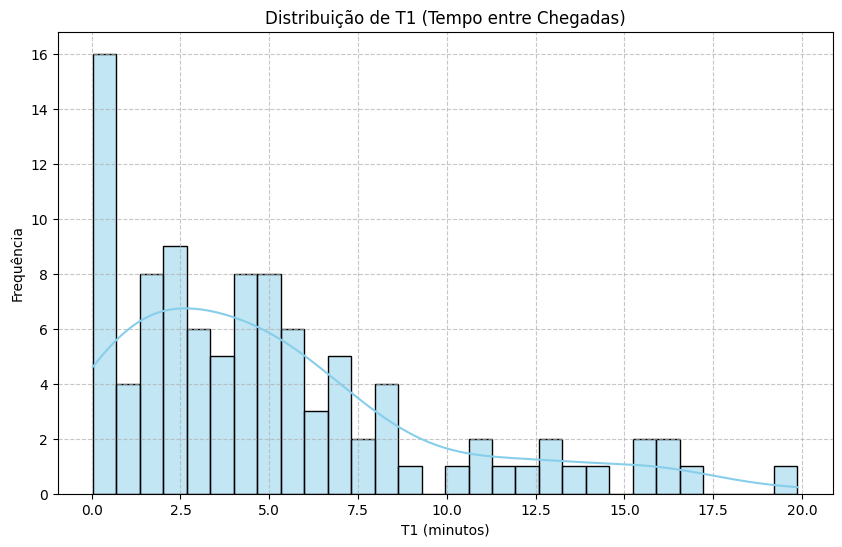

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize T1 distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_final_ocorrencias['T1'], kde=True, bins=30, color='skyblue')
plt.title('Distribuição de T1 (Tempo entre Chegadas)')
plt.xlabel('T1 (minutos)')
plt.ylabel('Frequência')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


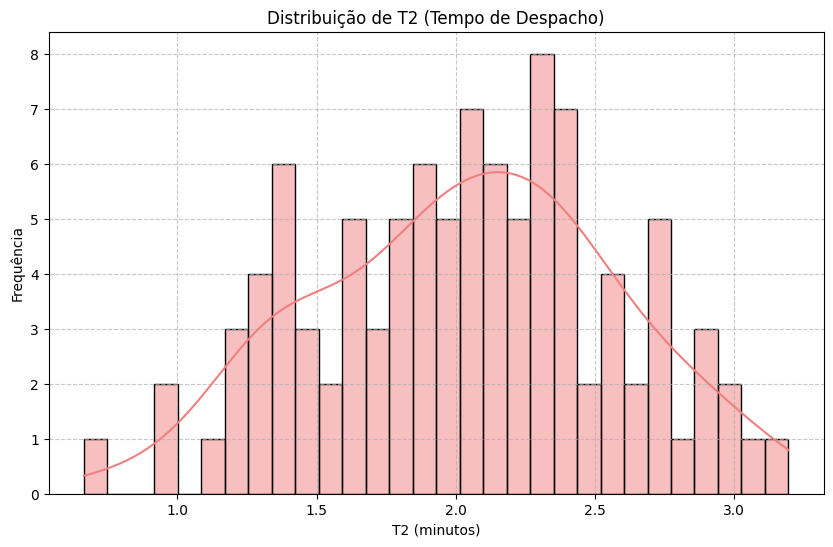

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize T2 distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_final_ocorrencias['T2'], kde=True, bins=30, color='lightcoral')
plt.title('Distribuição de T2 (Tempo de Despacho)')
plt.xlabel('T2 (minutos)')
plt.ylabel('Frequência')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


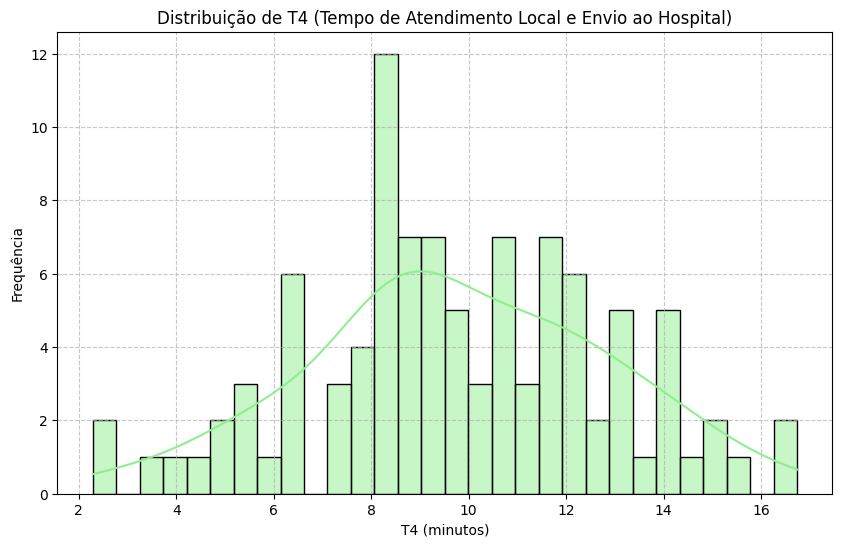

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize T4 distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_final_ocorrencias['T4'], kde=True, bins=30, color='lightgreen')
plt.title('Distribuição de T4 (Tempo de Atendimento Local e Envio ao Hospital)')
plt.xlabel('T4 (minutos)')
plt.ylabel('Frequência')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


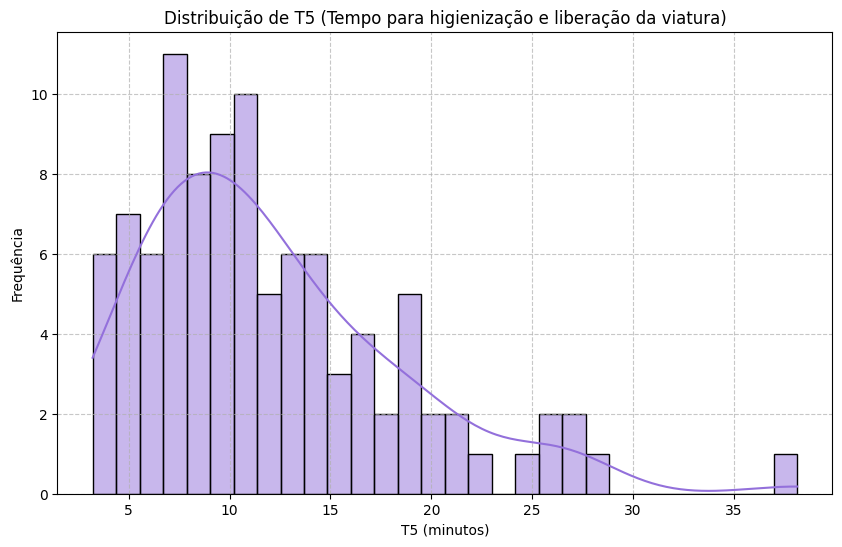

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize T5 distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_final_ocorrencias['T5'], kde=True, bins=30, color='mediumpurple')
plt.title('Distribuição de T5 (Tempo para higienização e liberação da viatura)')
plt.xlabel('T5 (minutos)')
plt.ylabel('Frequência')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# 2. Cálculo dos clusters para um conjunto de pontos dados

## 2.1. Aplicação de um método de clusterização

In [ ]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import SpectralClustering
from sklearn.cluster import AgglomerativeClustering

dict_of_methods = {'Kmeans':"KMeans(n_clusters = n_clusters, init = 'k-means++', random_state = 42)",
                   'gmmcluster':"GaussianMixture(n_components=n_clusters, random_state=42)",
                   'spectral':"SpectralClustering(n_clusters = n_clusters, random_state=42)",
                   'aglomerative':"AgglomerativeClustering(n_clusters = n_clusters,linkage='complete',metric='manhattan')"} # Changed affinity to metric
dict_of_centers = {'Kmeans':'cluster_centers_', 'gmmcluster':'means_', 'spectral':'means(df_accident, model)', 'aglomerative':'means(df_accident, model)'}


def means(df_accident, model, n_clusters):
  print('Manual computation of clusters centers...')
  # Obtaining input of the model
  X = df_accident.loc[:, ['Latitude', 'Longitude']].values
  # Obtenha os rótulos dos clusters
  cluster_labels = model.labels_

  # Calcular os centros dos clusters
  cluster_centers = []
  for cluster_id in range(n_clusters):  # Supondo que você tenha 3 clusters
    cluster_points = X[cluster_labels == cluster_id]
    cluster_center = np.mean(cluster_points, axis=0)
    cluster_centers.append(cluster_center)

  # Converta os centros dos clusters para um único array
  cluster_centers_array = np.vstack(cluster_centers)

  return cluster_centers_array

def get_dict_center_clusters(centers_clusters):
  print('Creating dictionary of cluster centers...')
  centers_dict = {}
  #centers_dict['1']=centers_clusters[0]
  for i in range(1,len(centers_clusters)+1):
    centers_dict[str(i)] = centers_clusters[i-1]

  return centers_dict

def evaluate_model(df_accident, method_name, n_clusters = 3):
  print('Starting to evalute model '+method_name+'...')
  # Obtaining input of the model
  print('Extracting input...')
  X = df_accident.loc[:, ['Latitude', 'Longitude']].values # Changed from 'lat', 'lon' to 'Latitude', 'Longitude'

  # According to the model name, running the according command
  print('Obtaining output labels...')
  model_command = dict_of_methods[method_name]
  model = eval(model_command)
  # Predicting labels using the method.
  y_model = model.fit_predict(X)
  df_accident[method_name+str(n_clusters)] = y_model +1 # to step up to group 1 to 3

  # Manual function to compute centers for method without an automatic one.
  if (method_name == 'spectral' or method_name == 'aglomerative'):
    model.means = means(df_accident, model, n_clusters)
    print(model)
    #center_clusters = model.cluster_centers_
    centers_clusters =  model.means#(df_accident, model, n_clusters)

  else:
    # Getting the center of the clusters
    print('Obtaining centers of the clusters...')
    get_centers = dict_of_centers[method_name]
    model_get_centers = 'model.'+get_centers
    centers_clusters = eval(model_get_centers)

  # Transforming the center of clusters into dictionary format
  centers_dict = get_dict_center_clusters(centers_clusters)
  print('... job done!')

  return df_accident, centers_dict

#model_name = 'Kmeans'
model_name = 'aglomerative'
n_clusters = 5
model_name_clusters = model_name + str(n_clusters)
df_accidents, centers_dict = evaluate_model(df_final_ocorrencias.rename(columns={'lat': 'Latitude', 'lon': 'Longitude'}), model_name, n_clusters = n_clusters)
print('Centers_dict = ',centers_dict)
df_accidents

Starting to evalute model aglomerative...
Extracting input...
Obtaining output labels...
Manual computation of clusters centers...
AgglomerativeClustering(linkage='complete', metric='manhattan', n_clusters=5)
Creating dictionary of cluster centers...
... job done!
Centers_dict =  {'1': array([-22.77409712, -46.97251345]), '2': array([-22.98586452, -47.09434238]), '3': array([-22.86590801, -46.93457905]), '4': array([-22.85922184, -47.10570827]), '5': array([-22.96898832, -47.18252816])}


,ID,Latitude,Longitude,T1,T2,T4,T5,municipio_nome,Populacao_2024,aglomerative5
0,Campinas-0000,-22.840905,-47.043604,1.145350,1.540692,9.780463,8.376660,Campinas,200000,4
1,Campinas-0001,-22.987483,-47.152249,4.929483,2.410142,15.388296,4.810166,Campinas,200000,2
2,Campinas-0002,-22.831299,-47.120423,0.379293,2.987134,8.454017,17.046337,Campinas,200000,4
3,Campinas-0003,-22.904539,-47.086880,1.787925,2.611866,9.229068,10.009031,Campinas,200000,2
4,Campinas-0004,-22.849546,-47.104293,3.281820,1.511919,12.714257,13.384657,Campinas,200000,4
...,...,...,...,...,...,...,...,...,...,...
95,Campinas-0095,-22.921608,-47.106628,2.974256,2.840511,4.072033,38.137683,Campinas,200000,4
96,Campinas-0096,-22.828335,-47.055936,0.537348,2.314679,4.836509,4.261461,Campinas,200000,4
97,Campinas-0097,-22.795335,-47.034767,1.942213,2.298282,7.873702,25.763429,Campinas,200000,1
98,Campinas-0098,-22.871490,-47.087167,4.482212,1.475965,8.213221,3.336359,Campinas,200000,4


## 2.2. Tempo total do serviço

In [ ]:
# Calculate 'Total_Time' as the sum of T1, T2, T4, and T5
df_accidents['Total_Time'] = df_accidents['T1'] + df_accidents['T2'] + df_accidents['T4'] + df_accidents['T5']
df_accidents['Total_Time']

,Total_Time
0,20.843166
1,27.538087
2,28.866780
3,23.637891
4,30.892653
...,...
95,48.024483
96,11.949997
97,37.877626
98,17.507756


## 2.3. Visualização em um mapa dos clusters encontrados

In [ ]:
from scipy.spatial import ConvexHull
import folium
import numpy as np

point_colors_dict = {'1': 'blue', '2':'red', '3':'orange', '4': 'green',
                     '5': 'lightblue', '6': 'lightred', '7':'beige', '8': 'lightgreen',
                     '9': 'darkblue', '10': 'darkred', '11': 'pink', '12': 'darkgreen',
                     '13':'purple', '14': 'darkpurple', '15': 'cadetblue', '16': 'gray'}

def create_map(df_accidents, location = [37.7978646118572,	-122.406667932388], zoom_start=12): # Adjusted zoom_start to 12

  # Calculate the center of the points
  center_lat = df_accidents['Latitude'].mean()
  center_lon = df_accidents['Longitude'].mean()

  # Potential fix for 403 error: If you experience a 403 error, it might be due to the default
  # tile provider (OpenStreetMap) rate limits or access issues. You can try changing it.
  # For example, to use 'Stamen Terrain', change the line below to:
  # map_osm = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles='Stamen Terrain')
  # Other options include 'CartoDB positron', 'CartoDB darkmatter', etc.
  map_osm = folium.Map(location=[center_lat, center_lon], tiles='CartoDB positron', zoom_start=zoom_start)

  # Adjust zoom to fit all points, ensuring it doesn't zoom too far out
  min_lat, max_lat = df_accidents['Latitude'].min(), df_accidents['Latitude'].max()
  min_lon, max_lon = df_accidents['Longitude'].min(), df_accidents['Longitude'].max()
  map_osm.fit_bounds([[min_lat, min_lon], [max_lat, max_lon]])

  return map_osm

def draw_points_clustered(map_osm, df_accidents, model_name):
  # Creating and adding to the map the Feature Group for each cluster.
  fgc_dict = {}
  for cluster in np.sort(df_accidents[model_name].unique()):
      fgc_dict[str(cluster)] = folium.FeatureGroup(name='Points '+str(cluster))
      map_osm.add_child(fgc_dict[str(cluster)])

  for _, row in df_accidents.iterrows():

      cluster = str(row[model_name])

      folium.CircleMarker(location=[row["Latitude"], row["Longitude"]],
                          radius=5,
                          fill_color=point_colors_dict[cluster],
                          popup=cluster).add_to(fgc_dict[cluster])

  return map_osm

def create_polygons(map_osm, df_accidents, model_name):

  polygon_dict = {}
  center_dict  = {}

  for g in np.sort(df_accidents[model_name].unique()):

    # first, we have to cut the lat lon in each group
    latlon_cut =df_accidents[df_accidents[model_name]==g].loc[:, ['Latitude', 'Longitude']]

    # second, scipy already provides  the great function for ConvexHull
    # we just throw our dataframe with lat lon in this function
    hull = ConvexHull(latlon_cut.values)
    # and with magic, we can have new lat lon boundary of each group
    Lat = latlon_cut.values[hull.vertices,0]
    Long = latlon_cut.values[hull.vertices,1]
    # the we create dataframe boundary and convert it to list of lat lon
    # for plotting polygon in folium
    cluster = pd.DataFrame({'lat':Lat,'lon':Long })
    area = list(zip(cluster['lat'],cluster['lon']))
    #---------------------#
    # plot polygon        #
    #---------------------#
    polygon_dict[str(g)] = folium.FeatureGroup(name= '<u><b>Area %d</b></u>'%(g),show= True)
    folium.Polygon(locations=area,
                   color=point_colors_dict[str(g)],
                   weight=2,
                   fill=True,
                   fill_opacity=0.1,
                   opacity=0.8).add_to(polygon_dict[str(g)])

    map_osm.add_child(polygon_dict[str(g)])

    #----------------------#
    # plot cluster centers #
    #----------------------#
    center_dict[str(g)] = folium.FeatureGroup(name= '<u><b>Center %d</b></u>'%(g),show= True)
    # Using a standard icon
    #print('g = ',str(g))
    #print('Color = ',point_colors_dict[str(g))]
    default_icon = folium.Icon(color=point_colors_dict[str(g)], icon='ambulance', prefix='fa')
    # Adding the marker to the map
    lat = centers_dict[str(g)][0]
    lon = centers_dict[str(g)][1]
    folium.Marker(location=[lat, lon], popup='Center '+str(g), icon=default_icon).add_to(center_dict[str(g)])
    map_osm.add_child(center_dict[str(g)])

  # to let the map have selectd layer1 layer2 you created
  #folium.LayerControl(collapsed=False,position= 'bottomright').add_to(map_osm)

  return map_osm

map_osm = create_map(df_accidents)
map_osm = draw_points_clustered(map_osm, df_accidents, model_name_clusters)
map_osm = create_polygons(map_osm, df_accidents, model_name_clusters)
map_osm.add_child(folium.LayerControl(collapsed=False, position='bottomright'))
map_osm

# 3. Computing in detail the distance from the clusters to the occurrences and the corresponding map

## 3.1. Computing the distance

In [ ]:
!pip install polyline

In [ ]:
import polyline
import requests

def get_route(origem, destino):
    pickup_lon = origem[1]
    pickup_lat = origem[0]
    dropoff_lon = destino[1]
    dropoff_lat = destino[0]

    loc = "{},{};{},{}".format(pickup_lon, pickup_lat, dropoff_lon, dropoff_lat)
    url = "https://router.project-osrm.org/route/v1/driving/"
    r = requests.get(url + loc)
    if r.status_code!= 200:
        return {}

    res = r.json()
    routes = polyline.decode(res['routes'][0]['geometry'])
    start_point = [res['waypoints'][0]['location'][1], res['waypoints'][0]['location'][0]]
    end_point = [res['waypoints'][1]['location'][1], res['waypoints'][1]['location'][0]]
    distance = res['routes'][0]['distance']/1000 # Converting from meters to kilometers

    out = {'route':routes,
           'start_point':start_point,
           'end_point':end_point,
           'distance':distance
          }

    return out

def routeDistance(origem, destino):
    coord_o = f'{origem[1]},{origem[0]}'
    coord_d = f'{destino[1]},{destino[0]}'

    r = requests.get(f'https://router.project-osrm.org/route/v1/driving/{coord_o};{coord_d}?steps=true&overview=false').json()
    #r = requests.get(f'https://router.project-osrm.org/route/v1/driving/{coord_o};{coord_d}?overview=false').json()
    #print(r["routes"][0]["legs"])

    if "routes" in r:
      distance = r["routes"][0]["distance"] / 1000
    else:
      distance = 0

    return distance

def stagesCosts(origem, hub):
  ## Drawing production nodes.
  vD_log_e1 = []
  vD_route_e1 = []
  print('Origem',origem)
  for index,row in origem.iterrows():
    D_log_e1 = []
    D_route_e1 = []
    xlat = row['Latitude']
    xlon = row['Longitude']

    for index,row in hub.iterrows():
      ylat = row['Latitude']
      ylon = row['Longitude']
      out = get_route([xlat, xlon], [ylat, ylon])
      rdist = out['distance']
      route_points = out['route']
      D_log_e1.append(rdist)
      D_route_e1.append(route_points)

    vD_log_e1.append(D_log_e1)
    vD_route_e1.append(D_route_e1)

  return vD_log_e1, vD_route_e1


def get_dist_paths_centers(model_name, centers_dict):

  centers_clusters = list(centers_dict.values())
  df_centers = pd.DataFrame(centers_clusters, columns=['Latitude', 'Longitude'])
  vD_log_e1 = {}
  vD_route_e1 = {}
  for g in np.sort(df_accidents[model_name].unique()):

    # first, we have to cut the lat lon in each group
    print(df_centers)
    origem  = pd.DataFrame(df_centers.loc[g-1:g-1])
    print(origem)
    destino = df_accidents[df_accidents[model_name]==g].loc[:, ['Latitude', 'Longitude']]
    print(destino)
    log_e1, route_e1 = stagesCosts(origem, destino)

    vD_log_e1[str(g)] = log_e1
    vD_route_e1[str(g)] = route_e1

  return vD_log_e1, vD_route_e1

vD_log_e1, vD_route_e1 = get_dist_paths_centers(model_name_clusters, centers_dict)
print(vD_log_e1)
print(vD_route_e1)

    Latitude  Longitude
0 -22.774097 -46.972513
1 -22.985865 -47.094342
2 -22.865908 -46.934579
3 -22.859222 -47.105708
4 -22.968988 -47.182528
    Latitude  Longitude
0 -22.774097 -46.972513
     Latitude  Longitude
11 -22.770422 -47.030137
13 -22.804074 -46.940994
14 -22.798183 -46.896467
16 -22.816105 -46.903648
21 -22.776787 -46.972251
25 -22.750159 -47.100712
36 -22.745561 -46.938991
39 -22.776465 -46.923180
41 -22.736983 -46.947238
46 -22.762345 -46.958597
48 -22.756278 -46.936874
49 -22.750901 -46.989617
50 -22.752122 -47.101303
58 -22.810166 -46.918619
61 -22.819851 -46.902505
65 -22.755886 -47.034664
66 -22.776048 -47.063673
70 -22.773589 -46.907238
72 -22.743219 -47.025215
73 -22.807909 -46.926309
76 -22.769434 -47.000694
82 -22.759036 -46.934864
90 -22.771472 -46.951766
97 -22.795335 -47.034767
Origem     Latitude  Longitude
0 -22.774097 -46.972513
    Latitude  Longitude
0 -22.774097 -46.972513
1 -22.985865 -47.094342
2 -22.865908 -46.934579
3 -22.859222 -47.105708
4 -22.96

In [ ]:
def get_total_distance(vD_log_e1):
  total_distance = 0
  for cluster in vD_log_e1:
    total_distance = total_distance + sum(vD_log_e1[cluster][0])

  return total_distance

total_distance = get_total_distance(vD_log_e1)
print('Total distance = ', total_distance)

Total distance =  1081.6544


## 3.2. Drawing the map of routes between the centers of the clusters and the occurrances

In [ ]:
def get_route_map(folium_group, name, route, color, initial_map=None):

  # If there is no initial map, create one centered on a general location
  if initial_map is None:
    initial_map = folium.Map(location=[-16.089461610967666, -55.910299337040286], zoom_start=5.5, tiles="cartodbpositron")

  folium.PolyLine(route,
                  weight=8,
                  color=color,
                  opacity=0.2).add_to(folium_group)

  initial_map.add_child(folium_group)

  return initial_map

def get_first_mile_routes(regions_dict, list_routes, df_accidents, model_name_clusters, centers_dict):
  colors = list(point_colors_dict.values())
  re_names = list(regions_dict.keys())

  # Calculate the center of the points for initial map view
  center_lat = df_accidents['Latitude'].mean()
  center_lon = df_accidents['Longitude'].mean()

  # Create the initial map centered on the points
  initial_map = folium.Map(location=[center_lat, center_lon], tiles='CartoDB positron', zoom_start=12)

  # Adjust zoom to fit all points
  min_lat, max_lat = df_accidents['Latitude'].min(), df_accidents['Latitude'].max()
  min_lon, max_lon = df_accidents['Longitude'].min(), df_accidents['Longitude'].max()
  initial_map.fit_bounds([[min_lat, min_lon], [max_lat, max_lon]])

  # Add demand points (occurrences) to the map
  initial_map = draw_points_clustered(initial_map, df_accidents, model_name_clusters)

  # Add polygons and cluster centers to the map
  initial_map = create_polygons(initial_map, df_accidents, model_name_clusters)

  # Add the routes for each cluster
  service_dict = {}
  for name, color, routes_for_cluster in zip(re_names, colors, list_routes.values()):
    service_fg = folium.FeatureGroup(name='Rotas ' + name, show=True)
    for route_path in routes_for_cluster[0]: # routes_for_cluster[0] contains a list of routes
        folium.PolyLine(route_path,
                        weight=3,
                        color=color,
                        opacity=0.7).add_to(service_fg)
    service_fg.add_to(initial_map)

  # Add LayerControl to the map
  initial_map.add_child(folium.LayerControl(collapsed=False, position='bottomright'))

  return initial_map

# regions_dict = {'R1':1, 'R2':2, 'R3':3}
regions_dict = {}
cont = 1
for key in centers_dict.keys():
  regions_dict['R'+key] = cont
  cont = cont + 1

dist_map_osm = get_first_mile_routes(regions_dict, vD_route_e1, df_accidents, model_name_clusters, centers_dict)
dist_map_osm

## 3.3. Relatório de Tempos Médios e Máximos por Cluster

In [ ]:
report_df = df_accidents.groupby(model_name_clusters)[['T1', 'T2', 'T4', 'T5']].agg(['mean', 'max'])
report_df.columns = ['_'.join(col).strip() for col in report_df.columns.values]
display(report_df)

,T1_mean,T1_max,T2_mean,T2_max,T4_mean,T4_max,T5_mean,T5_max
aglomerative5,,,,,,,,
1,6.233214,19.869586,2.009161,2.878193,9.953524,14.991557,10.743752,25.763429
2,5.077185,16.342217,1.931163,2.707932,9.693728,15.388296,13.104079,26.596258
3,4.246560,14.469702,2.058844,3.000172,10.065633,16.740354,12.132485,27.902988
4,4.588172,15.722176,2.082369,3.196639,9.553395,15.126911,12.195711,38.137683
5,5.710843,15.994996,2.103434,3.103487,9.440411,12.928055,13.069513,27.197866


## 3.4. Cálculo da Distância Média e Máxima do Centro do Cluster aos Pontos de Demanda

In [ ]:
distance_stats = {}
for cluster_id, distances_list in vD_log_e1.items():
    # distances_list contains a list of lists, where the inner list has distances for one hub (cluster center)
    # to all its demand points. We assume there's only one hub per cluster here, so we take distances_list[0].
    distances = distances_list[0]
    if distances:
        mean_dist = np.mean(distances)
        max_dist = np.max(distances)
        distance_stats[cluster_id] = {'mean_distance_km': mean_dist, 'max_distance_km': max_dist}
    else:
        distance_stats[cluster_id] = {'mean_distance_km': 0, 'max_distance_km': 0}

df_distance_stats = pd.DataFrame.from_dict(distance_stats, orient='index')
df_distance_stats.index.name = 'Cluster'
display(df_distance_stats)

,mean_distance_km,max_distance_km
Cluster,,
1,11.273987,23.5967
2,10.667900,18.3291
3,12.347069,29.0860
4,8.648195,17.1155
5,10.583691,14.9913


## 3.5. Cálculo de intervalos de confiança

In [ ]:
from scipy import stats
import math

def calculate_confidence_interval(data, confidence=0.95):
    if len(data) < 2:
        return float('nan'), float('nan') # Not enough data to calculate CI

    mean = np.mean(data)
    std_err = stats.sem(data) # Standard error of the mean
    n = len(data)

    # Use t-distribution for small samples or when population standard deviation is unknown
    h = std_err * stats.t.ppf((1 + confidence) / 2., n - 1)
    return mean - h, mean + h


### 3.5.1. Intervalos de Confiança para o Tempo Total (T1 + T2 + T4 + T5) por Cluster e Total

Calculamos o intervalo de confiança de 95% para o tempo médio total (T1 + T2 + T4 + T5) para cada cluster e para o conjunto total de ocorrências. Isso nos dá uma estimativa da precisão do tempo médio total.

In [ ]:
# Calculate Confidence Interval for Total_Time per cluster
total_time_cis = {}
for cluster_id in df_accidents[model_name_clusters].unique():
    total_time_data = df_accidents[df_accidents[model_name_clusters] == cluster_id]['Total_Time'].values
    if len(total_time_data) > 1:
        lower, upper = calculate_confidence_interval(total_time_data)
        total_time_cis[cluster_id] = {'Total_Time_mean_CI_lower': lower, 'Total_Time_mean_CI_upper': upper}
    else:
        total_time_cis[cluster_id] = {'Total_Time_mean_CI_lower': float('nan'), 'Total_Time_mean_CI_upper': float('nan')}

df_total_time_cis = pd.DataFrame.from_dict(total_time_cis, orient='index')
df_total_time_cis.index.name = 'Cluster'
display(df_total_time_cis)

# Calculate Confidence Interval for Total_Time for all clusters combined
all_total_time_data = df_accidents['Total_Time'].values
all_total_time_lower, all_total_time_upper = calculate_confidence_interval(all_total_time_data)
print(f"\nIntervalo de Confiança de 95% para o Tempo Total: ({all_total_time_lower:.2f}, {all_total_time_upper:.2f}) minutos")

,Total_Time_mean_CI_lower,Total_Time_mean_CI_upper
Cluster,,
4,24.539447,32.299847
2,24.900189,34.712121
3,24.894091,32.112953
1,26.022239,31.857063
5,25.099230,35.549171



Intervalo de Confiança de 95% para o Tempo Total: (27.37, 30.68) minutos


### 3.5.2. Intervalos de Confiança para Distância Percorrida por Cluster e Total

Similarmente, calculamos o intervalo de confiança de 95% para a distância média percorrida do centro do cluster aos pontos de demanda. Isso nos ajuda a entender a variação nas distâncias de atendimento.


In [ ]:
# Calculate Confidence Interval for distance per cluster
distance_cis = {}
for cluster_id, distances_list in vD_log_e1.items():
    # Flatten the list of lists of distances for the current cluster
    # Assuming distances_list[0] contains the distances from the cluster center to its points
    distances = distances_list[0]
    if len(distances) > 1:
        lower, upper = calculate_confidence_interval(distances)
        distance_cis[cluster_id] = {'Distance_mean_CI_lower': lower, 'Distance_mean_CI_upper': upper}
    else:
        distance_cis[cluster_id] = {'Distance_mean_CI_lower': float('nan'), 'Distance_mean_CI_upper': float('nan')}

df_distance_cis = pd.DataFrame.from_dict(distance_cis, orient='index')
df_distance_cis.index.name = 'Cluster'
display(df_distance_cis)

# Calculate Confidence Interval for distance for all clusters combined
all_distances_data = []
for cluster_id, distances_list in vD_log_e1.items():
    all_distances_data.extend(distances_list[0])

all_distances_lower, all_distances_upper = calculate_confidence_interval(all_distances_data)
print(f"\nIntervalo de Confiança de 95% para Distância Total: ({all_distances_lower:.2f}, {all_distances_upper:.2f}) km")


,Distance_mean_CI_lower,Distance_mean_CI_upper
Cluster,,
1,8.407532,14.140443
2,9.061391,12.274409
3,9.758806,14.935333
4,6.919337,10.377054
5,8.125481,13.041901



Intervalo de Confiança de 95% para Distância Total: (9.75, 11.88) km
